# 🧪 08 - Pandas Wrangle Lab: Clean and Explore a Messy Purchases Dataset

A retail company has sent you `messy_purchases.csv`. Each row is supposed to be **one purchase**, but the file has every problem from this module:
- Prices stored as text, with dollar signs and commas (`'$1,249.99'`)
- Placeholder values like `'Unknown'`, `'not recorded'`, and `-1`
- State and department names with inconsistent capitals, spaces, and spellings (`'il '`, `'Illinois'`)
- Dates stored as text, in three different formats
- Duplicate purchases, and messy column names
- A column that isn't needed for the analysis

Your job: produce a **clean** dataset you can trust, then answer business questions about **revenue by state and department**. Work through the sections in order; each one uses a notebook from this module.

## ✅ Learning Goals
- Practice loading, cleaning, and exploring real-world-ish data, from start to finish
- Detect and handle missing values, placeholders, duplicates, and type mismatches
- Apply column creation, renaming, conditional updates, sorting, and filtering together
- Use `.info()`, `.describe()`, `.value_counts()`, and `.query()` fluently
- Group and summarize with `.groupby()`, then validate and export the results

```text
Load → Inspect → Standardize text and placeholders → Fix types
     → Handle missing values and duplicates → Create columns
     → Filter, sort, and summarize → Validate and export
```

## 0. Setup
Everything this lab saves goes into **`08-OutputFiles`** (the same pattern as Foundations). Upload that folder along with this notebook.

In [1]:
import pandas as pd
from pathlib import Path

OUT = Path('08-OutputFiles')
OUT.mkdir(exist_ok=True)

## 1. Load and Look (Change Nothing Yet)
Inspect before you clean (notebook 02). Don't change anything in this section, just look.

In [2]:
purchases = pd.read_csv('messy_purchases.csv')
purchases.head()

,Purchase ID,buyer_id,Product Name,Department,State,Purchase Date,Unit Price,QTY,Supplier Note
0,50140,28,Throw Blanket,Home,MN,03/09/2026,$29.99,3,clearance
1,50187,58,Backpack,Travel,IL,06/17/2026,$39.99,2,seasonal
2,50144,55,Notebook,Office,WI,"Jun 17, 2026",4.99,3,seasonal
3,50174,49,Backpack,Travel,IL,2026-06-14,39.99,2,standard
4,50012,60,Notebook,Office,il,2026-02-28,$4.99,1,clearance


In [3]:
print('shape:', purchases.shape)
print('columns:', purchases.columns.tolist())

shape: (269, 9)
columns: ['Purchase ID', 'buyer_id', 'Product Name', ' Department', 'State', 'Purchase Date', ' Unit Price ', 'QTY', 'Supplier Note']


In [4]:
purchases.info()

<class 'pandas.DataFrame'>
RangeIndex: 269 entries, 0 to 268
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   Purchase ID    269 non-null    int64
 1   buyer_id       269 non-null    int64
 2   Product Name   269 non-null    str  
 3    Department    268 non-null    str  
 4   State          263 non-null    str  
 5   Purchase Date  267 non-null    str  
 6    Unit Price    263 non-null    str  
 7   QTY            265 non-null    str  
 8   Supplier Note  269 non-null    str  
dtypes: int64(2), str(7)
memory usage: 19.0 KB


In [5]:
purchases.describe(include='all')

,Purchase ID,buyer_id,Product Name,Department,State,Purchase Date,Unit Price,QTY,Supplier Note
count,269.000000,269.000000,269,268,263,267,263,265,269
unique,NaN,NaN,28,18,18,190,43,7,4
top,NaN,NaN,Notebook,Office,IL,2026-05-02,$4.99,1,standard
freq,NaN,NaN,43,74,67,4,27,99,131
mean,50130.847584,31.591078,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,75.036925,16.887801,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,50001.000000,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,50067.000000,17.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,50132.000000,31.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,50195.000000,47.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
purchases.isnull().sum()

Purchase ID      0
buyer_id         0
Product Name     0
 Department      1
State            6
Purchase Date    2
 Unit Price      6
QTY              4
Supplier Note    0
dtype: int64

✍️ **Before going on, note your answers:**
1. How many rows and columns are there? shape: (269, 9)
columns: ['Purchase ID', 'buyer_id', 'Product Name', ' Department', 'State', 'Purchase Date', ' Unit Price ', 'QTY', 'Supplier Note']
2. Which columns have missing values? [' Department', 'State', 'Purchase Date', ' Unit Price ', 'QTY']
3. Which columns *look* numeric but are stored as text? (`Unit Price`? `QTY`?) [' Department', ' Unit Price ', 'QTY']
4. Are the dates real dates, or text? text
5. Do the column names need cleaning? (Look closely at `' Department'` and `' Unit Price '`.)

*Your answers here.*

## 2. Make a Working Copy
Keep the raw data untouched, so you can compare before and after (notebook 04):

```text
raw data            → purchases
working clean copy  → clean
```

In [8]:
clean = purchases.copy()

## 3. Standardize the Column Names
Fix the names **first**, because every later line depends on them (notebook 05):

In [9]:
clean.columns = clean.columns.str.strip().str.lower().str.replace(' ', '_')
clean = clean.rename(columns={'qty': 'quantity'})
clean.columns.tolist()

['purchase_id',
 'buyer_id',
 'product_name',
 'department',
 'state',
 'purchase_date',
 'unit_price',
 'quantity',
 'supplier_note']

## 4. Inspect the Categories
Text categories hide spelling differences, stray spaces, and placeholders. `value_counts(dropna=False)` shows them all:

In [10]:
clean['state'].value_counts(dropna=False)

state
IL           67
WI           44
MN           29
IA           22
IN           18
Illinois     14
IL           11
il           10
wi            9
Minnesota     6
Wisconsin     6
NaN           6
IN            5
Iowa          5
Indiana       4
MN            4
mn            4
Unknown       3
in            2
Name: count, dtype: int64

In [11]:
clean['department'].value_counts(dropna=False)

department
Office          74
Travel          49
Home            36
Electronics     29
office          14
 Office         12
 Travel         11
electronics      7
TRAVEL           6
OFFICE           6
travel           6
home             5
ELECTRONICS      3
Unknown          3
HOME             2
 Home            2
 Electronics     2
unknown          1
NaN              1
Name: count, dtype: int64

Five real states appear as nearly twenty "different" values: `'IL'`, `'il'`, `'IL '`, `'Illinois'`, ...

💡 Where did `'N/A'` and the blank cells go? `pd.read_csv` **already** turns a few common placeholders, including blanks, `'N/A'`, `'NA'`, and `'null'`, into `NaN` while loading. That's why they show up as `NaN` above. It **doesn't** know about `'Unknown'`, `'not recorded'`, or `-1`. Those are up to you.


## 5. Standardize the Text
Strip spaces and fix capitalization, then map long names to codes (notebook 04). `.astype('string')` makes sure every value is text before using `.str`:

In [12]:
for col in ['state', 'department', 'product_name']:
    clean[col] = clean[col].astype('string').str.strip()

clean['state'] = clean['state'].str.upper().replace({
    'ILLINOIS': 'IL', 'WISCONSIN': 'WI', 'MINNESOTA': 'MN', 'INDIANA': 'IN', 'IOWA': 'IA',
})
clean['department'] = clean['department'].str.title()

clean['state'].value_counts(dropna=False)

state
IL         102
WI          59
MN          43
IN          29
IA          27
<NA>         6
UNKNOWN      3
Name: count, dtype: Int64

## 6. Replace Placeholders with Real Missing Values
Now that the text is standardized, the placeholders are predictable: `'UNKNOWN'` in `state` (it was upper-cased), and `'Unknown'` in `department` (title-cased). Replace them **column by column** with a nested dictionary (notebook 04):

⚠️ Standardize **before** replacing. If you replaced `'UNKNOWN'` in `department` after title-casing, nothing would match, because it's spelled `'Unknown'` by then.

In [13]:
clean = clean.replace({
    'state':         {'UNKNOWN': pd.NA},
    'department':    {'Unknown': pd.NA},
    'unit_price':    {'-1': pd.NA},
    'quantity':      {'-1': pd.NA},
    'purchase_date': {'not recorded': pd.NA},
})

print('Missing cells in total:', clean.isna().sum().sum())
clean.isna().sum()

Missing cells in total: 34


purchase_id      0
buyer_id         0
product_name     0
department       5
state            9
purchase_date    6
unit_price       7
quantity         7
supplier_note    0
dtype: int64

In [14]:
# Rows with at least one missing value
clean[clean.isna().any(axis=1)].head()

,purchase_id,buyer_id,product_name,department,state,purchase_date,unit_price,quantity,supplier_note
5,50059,53,Pen Set,Office,MN,2026-06-17,7.49,NaN,clearance
25,50136,16,Desk Lamp,Home,<NA>,"Jan 13, 2026",24.99,2,seasonal
46,50003,26,Water Bottle,Travel,IA,NaN,12.50,4,clearance
48,50110,17,Notebook,Office,WI,04/26/2026,NaN,1,clearance
50,50021,15,Luggage Tag,Travel,<NA>,03/07/2026,6.25,1,standard


## 7. Fix the Numbers
`unit_price` is text like `'$1,249.99'` and `' 4.99 '`. Remove the dollar signs, commas, and spaces, **then** convert. Keep the raw values, so you can see what failed (notebook 04). `regex=False` treats `$` as plain text (notebook 06):

In [15]:
raw_price = clean['unit_price'].copy()

clean['unit_price'] = (clean['unit_price']
                       .str.replace('$', '', regex=False)
                       .str.replace(',', '', regex=False)
                       .str.strip())
clean['unit_price'] = pd.to_numeric(clean['unit_price'], errors='coerce')

print('Prices that failed to convert:', raw_price[clean['unit_price'].isna() & raw_price.notna()].tolist())

Prices that failed to convert: []


`quantity` should be whole numbers, but one row says `'two'`, just like the `'ninety'` hiding in a score column in this lab's earlier version. It's a word, not a missing value, so `.isna()` never counted it. Convert with `errors='coerce'`, and use the nullable `'Int64'` type so the column can hold missing values (notebook 04):

In [16]:
raw_quantity = clean['quantity'].copy()
clean['quantity'] = pd.to_numeric(clean['quantity'], errors='coerce').astype('Int64')

print('Quantities that failed to convert:', raw_quantity[clean['quantity'].isna() & raw_quantity.notna()].tolist())
clean[['unit_price', 'quantity']].dtypes

Quantities that failed to convert: ['two']


unit_price    float64
quantity        Int64
dtype: object

## 8. Fix the Dates
The dates mix three formats (`2026-01-05`, `01/08/2026`, `Jan 8, 2026`). Watch what happens without `format='mixed'` (notebook 04):

In [17]:
guessed = pd.to_datetime(clean['purchase_date'], errors='coerce')
mixed = pd.to_datetime(clean['purchase_date'], errors='coerce', format='mixed')

print('Missing dates, format guessed:', guessed.isna().sum())
print("Missing dates, format='mixed':", mixed.isna().sum())

Missing dates, format guessed: 204
Missing dates, format='mixed': 6


Guessing the format from the first value would have thrown away most of the dates, **silently**. Use `format='mixed'`, then check the range and add a month column with `.dt` (notebook 05):

In [18]:
clean['purchase_date'] = mixed
print('From', clean['purchase_date'].min().date(), 'to', clean['purchase_date'].max().date())

clean['purchase_month'] = clean['purchase_date'].dt.to_period('M')
clean[['purchase_date', 'purchase_month']].head(3)

From 2026-01-02 to 2026-06-29


,purchase_date,purchase_month
0,2026-03-09,2026-03
1,2026-06-17,2026-06
2,2026-06-17,2026-06


## 9. Find and Remove Duplicates
Look **before** you delete (notebook 04). First, exact copies:

In [19]:
print('Exact duplicate rows:', clean.duplicated().sum())
clean[clean.duplicated(keep=False)].sort_values('purchase_id').head(6)

Exact duplicate rows: 6


,purchase_id,buyer_id,product_name,department,state,purchase_date,unit_price,quantity,supplier_note,purchase_month
127,50002,19,Stapler,Office,IL,2026-05-26,12.99,1,backorder,2026-05
151,50002,19,Stapler,Office,IL,2026-05-26,12.99,1,backorder,2026-05
13,50071,10,Throw Blanket,Home,MN,2026-04-05,29.99,1,seasonal,2026-04
155,50071,10,Throw Blanket,Home,MN,2026-04-05,29.99,1,seasonal,2026-04
201,50096,19,Notebook,Office,MN,2026-06-15,4.99,5,clearance,2026-06
83,50096,19,Notebook,Office,MN,2026-06-15,4.99,5,clearance,2026-06


In [20]:
clean = clean.drop_duplicates()
print('Repeated purchase IDs left:', clean.duplicated(subset=['purchase_id']).sum())

clean[clean.duplicated(subset=['purchase_id'], keep=False)].sort_values('purchase_id')[
    ['purchase_id', 'product_name', 'unit_price', 'quantity', 'purchase_date']]

Repeated purchase IDs left: 3


,purchase_id,product_name,unit_price,quantity,purchase_date
15,50141,USB Hub,21.50,4,2026-01-17
220,50141,USB Hub,21.50,3,2026-01-17
132,50222,Desk Lamp,24.99,3,2026-03-19
88,50222,Desk Lamp,24.99,2,2026-03-19
90,50227,Stapler,12.99,2,2026-05-06
73,50227,Stapler,12.99,3,2026-05-06


These rows share a `purchase_id` but have different quantities. Each **purchase** should appear once, and the company says later entries are **corrections**, so keep the last one. (Without that information, you'd need to ask! Never guess silently.)

In [21]:
clean = clean.drop_duplicates(subset=['purchase_id'], keep='last')
print('Rows now:', len(clean))

Rows now: 260


## 10. Fill or Drop?
Decide column by column (notebook 04):

| Column | Missing means... | Decision |
|---|---|---|
| `state`, `department` | Unknown, but the purchase is still real | **Fill** with `'NOT PROVIDED'` / `'Not Provided'` |
| `unit_price`, `quantity` | Can't compute revenue | **Drop** from the revenue analysis |
| `purchase_date` | Can't place it in time | **Drop** |
| `quantity` | Not "zero items"! | Never fill with `0` |

In [22]:
clean['state'] = clean['state'].fillna('NOT PROVIDED')
clean['department'] = clean['department'].fillna('Not Provided')

before = len(clean)
clean = clean.dropna(subset=['purchase_id', 'purchase_date', 'unit_price', 'quantity'])
print('Dropped', before - len(clean), 'rows missing an essential field. Rows now:', len(clean))

Dropped 21 rows missing an essential field. Rows now: 239


## 11. Create Useful Columns
Whole-column operations, a True/False flag, and bands with `pd.cut()` (notebook 05):

In [23]:
clean['revenue'] = clean['unit_price'] * clean['quantity']
clean['multi_item'] = clean['quantity'] >= 2
clean['revenue_category'] = pd.cut(clean['revenue'], bins=[0, 20, 100, float('inf')],
                                   labels=['Small', 'Medium', 'Large'])

clean[['product_name', 'unit_price', 'quantity', 'revenue', 'revenue_category']].head()

,product_name,unit_price,quantity,revenue,revenue_category
0,Throw Blanket,29.99,3,89.97,Medium
1,Backpack,39.99,2,79.98,Medium
2,Notebook,4.99,3,14.97,Small
3,Backpack,39.99,2,79.98,Medium
4,Notebook,4.99,1,4.99,Small


## 12. Update Only Matching Rows
Set a default, then apply each rule with `.loc[]`. The **last** matching rule wins, so the more generous large-order discount goes last (notebook 05):

In [ ]:
clean['discount_rate'] = 0.00
clean.loc[clean['department'] == 'Office', 'discount_rate'] = 0.10
clean.loc[clean['revenue'] >= 100, 'discount_rate'] = 0.15

clean['discounted_revenue'] = (clean['revenue'] * (1 - clean['discount_rate'])).round(2)
clean['discount_rate'].value_counts()

discount_rate
0.00    106
0.10     81
0.15     52
Name: count, dtype: int64

💡 We filled the missing departments in section 10 **first** for a reason. In a `'string'` column, comparing a missing value gives `<NA>` instead of `False`, and `.loc[]` refuses a mask that contains `<NA>`.

## 13. Drop What You Don't Need
Build the analysis table **without** changing `clean`, so the full version is still there (notebook 05):

In [25]:
analysis = clean.drop(columns=['supplier_note'], errors='ignore')
analysis.columns.tolist()

['purchase_id',
 'buyer_id',
 'product_name',
 'department',
 'state',
 'purchase_date',
 'unit_price',
 'quantity',
 'purchase_month',
 'revenue',
 'multi_item',
 'revenue_category',
 'discount_rate',
 'discounted_revenue']

## 14. Explore the Clean Data
Re-run the same inspection as section 1. What changed?

In [26]:
analysis.info()

<class 'pandas.DataFrame'>
Index: 239 entries, 0 to 268
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   purchase_id         239 non-null    int64         
 1   buyer_id            239 non-null    int64         
 2   product_name        239 non-null    string        
 3   department          239 non-null    string        
 4   state               239 non-null    string        
 5   purchase_date       239 non-null    datetime64[us]
 6   unit_price          239 non-null    float64       
 7   quantity            239 non-null    Int64         
 8   purchase_month      239 non-null    period[M]     
 9   revenue             239 non-null    Float64       
 10  multi_item          239 non-null    boolean       
 11  revenue_category    239 non-null    category      
 12  discount_rate       239 non-null    float64       
 13  discounted_revenue  239 non-null    Float64       
dtypes: Float64

In [27]:
analysis[['unit_price', 'quantity', 'revenue']].describe().round(2)

,unit_price,quantity,revenue
count,239.00,239.0,239.0
mean,35.39,2.3,85.0
std,87.48,1.34,194.25
min,4.99,1.0,4.99
25%,7.49,1.0,12.99
50%,18.75,2.0,29.96
75%,39.99,3.0,79.98
max,1249.99,5.0,2499.98


In [28]:
print(analysis['revenue_category'].value_counts().to_dict())
analysis['state'].value_counts(normalize=True).mul(100).round(1)

{'Medium': 103, 'Small': 84, 'Large': 52}


state
IL              38.5
WI              21.8
MN              15.5
IN              10.5
IA              10.0
NOT PROVIDED     3.8
Name: proportion, dtype: Float64

## 15. Filter
Masks, `.isin()`, and the rows-and-columns `.loc[]` pattern (notebooks 03 and 06):

In [29]:
office_in_il = (analysis['department'] == 'Office') & (analysis['state'] == 'IL')
print('Office purchases in IL:', office_in_il.sum())

neighbors = analysis['state'].isin(['IL', 'WI'])
print('Purchases in IL or WI: ', neighbors.sum())

analysis.loc[analysis['revenue'] >= 500, ['purchase_id', 'product_name', 'state', 'revenue']]

Office purchases in IL: 36
Purchases in IL or WI:  144


,purchase_id,product_name,state,revenue
16,50229,Standing Desk,WI,2499.98
91,50128,Monitor,WI,759.96
93,50246,Office Chair,WI,599.96
147,50250,Monitor,IN,759.96
217,50165,Office Chair,IN,599.96


## 16. Query
For long conditions, `.query()` reads like a sentence, and `@` brings in Python variables (notebook 06):

In [30]:
target_state = 'WI'
minimum_revenue = 100

analysis.query('state == @target_state and revenue >= @minimum_revenue and quantity >= 2')[
    ['purchase_id', 'product_name', 'quantity', 'revenue']]

,purchase_id,product_name,quantity,revenue
16,50229,Standing Desk,2,2499.98
20,50030,Backpack,4,159.96
26,50026,Monitor,2,379.98
41,50149,Throw Blanket,5,149.95
43,50162,Headphones,2,159.98
44,50163,Headphones,4,319.96
91,50128,Monitor,4,759.96
93,50246,Office Chair,4,599.96
109,50083,Headphones,4,319.96
130,50022,Headphones,4,319.96


## 17. Sort into a Report
Filter first, then pick columns, then sort (notebook 06):

In [31]:
top_purchases = (analysis
                 .loc[analysis['revenue'] >= 50, ['purchase_id', 'product_name', 'state', 'department', 'revenue']]
                 .sort_values('revenue', ascending=False))
top_purchases.head(10)

,purchase_id,product_name,state,department,revenue
16,50229,Standing Desk,WI,Office,2499.98
147,50250,Monitor,IN,Electronics,759.96
91,50128,Monitor,WI,Electronics,759.96
217,50165,Office Chair,IN,Office,599.96
93,50246,Office Chair,WI,Not Provided,599.96
134,50207,Headphones,IL,Electronics,399.95
161,50171,Headphones,IA,Electronics,399.95
26,50026,Monitor,WI,Electronics,379.98
109,50083,Headphones,WI,Electronics,319.96
130,50022,Headphones,WI,Electronics,319.96


## 18. Group and Summarize
Now the business questions (notebook 07). First, by state:

In [32]:
by_state = (analysis
            .groupby('state', as_index=False)
            .agg(purchases=('purchase_id', 'count'),
                 total_revenue=('revenue', 'sum'),
                 average_revenue=('revenue', 'mean'))
            .round(2)
            .sort_values('total_revenue', ascending=False))
by_state

,state,purchases,total_revenue,average_revenue
5,WI,52,7490.82,144.05
1,IL,92,5543.67,60.26
2,IN,25,2797.01,111.88
3,MN,37,2732.63,73.85
0,IA,24,1447.92,60.33
4,NOT PROVIDED,9,303.58,33.73


Illinois has the most purchases, but is it the top state for **revenue**? Counting rows and adding up money can tell different stories. Now by state **and** department; each row of the result is one `(state, department)` group:

In [33]:
by_state_department = (analysis
                       .groupby(['state', 'department'], as_index=False)
                       .agg(purchases=('purchase_id', 'count'),
                            total_revenue=('revenue', 'sum'),
                            largest_purchase=('revenue', 'max'))
                       .round(2)
                       .sort_values(['state', 'total_revenue'], ascending=[True, False]))
by_state_department.head(10)

,state,department,purchases,total_revenue,largest_purchase
0,IA,Electronics,5,651.94,399.95
4,IA,Travel,8,493.65,199.95
1,IA,Home,5,209.92,59.98
3,IA,Office,4,54.92,37.45
2,IA,Not Provided,2,37.49,24.99
8,IL,Travel,29,2067.08,199.95
5,IL,Electronics,12,1811.33,399.95
6,IL,Home,15,846.02,149.95
7,IL,Office,36,819.24,299.98
9,IN,Electronics,3,1057.45,759.96


## 19. Validate
Clean data isn't just data with fewer rows. Check that the cleaning did what you meant (notebook 04):

In [34]:
quality = pd.DataFrame({
    'raw':   {'rows': len(purchases),
              'missing cells': purchases.isna().sum().sum(),
              'exact duplicates': purchases.duplicated().sum()},
    'clean': {'rows': len(analysis),
              'missing cells': analysis.isna().sum().sum(),
              'exact duplicates': analysis.duplicated().sum()},
})
quality

,raw,clean
rows,269,239
missing cells,19,0
exact duplicates,6,0


In [35]:
print('Repeated purchase IDs:', analysis['purchase_id'].duplicated().sum())
print('Departments:', sorted(analysis['department'].unique()))
print('States:     ', sorted(analysis['state'].unique()))
analysis['revenue'].describe().round(2)

Repeated purchase IDs: 0
Departments: ['Electronics', 'Home', 'Not Provided', 'Office', 'Travel']
States:      ['IA', 'IL', 'IN', 'MN', 'NOT PROVIDED', 'WI']


count      239.0
mean        85.0
std       194.25
min         4.99
25%        12.99
50%        29.96
75%        79.98
max      2499.98
Name: revenue, dtype: Float64

Ask yourself:
- Are the essential columns complete? Are prices numbers, and dates real dates?
- Are the placeholder values gone, and do the state and department categories look standardized?
- Were the duplicate rules appropriate? Do the revenue values look reasonable?

Notice what the raw "missing cells" count **didn't** include: `'Unknown'`, `'not recorded'`, `'-1'`, and `'two'` were hiding in plain sight until sections 6 and 7. A missing-value report on raw data only counts what pandas can recognize.

## 20. Export
Reset the row labels (rows were dropped), then save the clean data and the summary report to `OUT` (Foundations notebook 06):

In [36]:
analysis = analysis.reset_index(drop=True)
analysis.to_csv(OUT / 'cleaned_purchases.csv', index=False)
by_state_department.to_csv(OUT / 'revenue_by_state_department.csv', index=False)
print('Saved:', sorted(p.name for p in OUT.glob('*.csv')))

Saved: ['cleaned_purchases.csv', 'revenue_by_state_department.csv']


## 🏋️ Practice

### Practice 1 — Verify the Cleanup (easy)
Confirm that `analysis` has **zero** missing values in `purchase_date`, `unit_price`, `quantity`, and `revenue`, and that it has fewer rows than `purchases`. Then print how many rows were removed in total, and what percentage of the raw data that is.

In [44]:
# Your code here
# Confirm zero missing values in the required columns
print(analysis[['purchase_date', 'unit_price', 'quantity', 'revenue']].isna().sum())

# Compare row counts
print('analysis shape :', analysis.shape)
print('purchases shape:', purchases.shape)

# Rows removed
rows_removed = len(purchases) - len(analysis)
pct_removed = rows_removed / len(purchases) * 100

print(f'Rows removed: {rows_removed}')
print(f'Percent removed: {pct_removed:.2f}%')


purchase_date    0
unit_price       0
quantity         0
revenue          0
dtype: int64
analysis shape : (239, 14)
purchases shape: (269, 9)
Rows removed: 30
Percent removed: 11.15%


### Practice 2 — Revenue Share (medium)
Using `groupby`, find each **department's** share of total revenue as a percentage (its revenue ÷ all revenue × 100), rounded to 1 decimal place and sorted from largest to smallest. Is it the same order as `analysis['department'].value_counts()`? Why or why not?

In [48]:
# Your code here
by_department_revenue = (
    analysis.groupby('department', as_index=False)
    .agg(dept_revenue=('revenue', 'sum'))
)

by_department_revenue['pct_of_total_revenue'] = (
    by_department_revenue['dept_revenue']
    / analysis['revenue'].sum()
    * 100
).round(1)

by_department_revenue = by_department_revenue.sort_values(
    'pct_of_total_revenue',
    ascending=False
)

by_department_revenue

,department,dept_revenue,pct_of_total_revenue
0,Electronics,7355.35,36.2
3,Office,6039.09,29.7
4,Travel,4056.67,20.0
1,Home,2193.07,10.8
2,Not Provided,671.45,3.3


In [49]:
analysis['department'].value_counts()

department
Office          90
Travel          66
Home            40
Electronics     38
Not Provided     5
Name: count, dtype: Int64

### Is it the same order as `analysis['department'].value_counts()`? Why or why not?
- No it's not the same. value_counts() ranks departments by number of transactions/purchases, while revenue share ranks departments by total dollars generated.

### Practice 3 — Group by a New Bucket (harder)
Create an `order_size` column that's `'Single'` when `quantity` is 1 and `'Multiple'` otherwise. Group by it and show the number of purchases, the total revenue, and the average revenue for each group.

In [50]:
# Your code here
# Create the order_size column
analysis['order_size'] = analysis['quantity'].apply(
    lambda x: 'Single' if x == 1 else 'Multiple'
)

# Group by order_size
order_summary = (
    analysis.groupby('order_size')
    .agg(
        purchases=('purchase_id', 'count'),
        total_revenue=('revenue', 'sum'),
        avg_revenue=('revenue', 'mean')
    )
    .round({'avg_revenue': 2, 'total_revenue': 2})
)

order_summary

,purchases,total_revenue,avg_revenue
order_size,,,
Multiple,149,18095.28,121.44
Single,90,2220.35,24.67


## ❓ Lab Questions
Answer each in the Markdown cell below, and use the code cell for any calculations:
1. What were the original dimensions of the dataset, and the final ones? original dimension was (269, 9) and the final has (239,14)
2. Which placeholder values did `read_csv` handle automatically, and which did you replace yourself?
3. Which columns needed type conversion, and why? Which **values** failed to convert?
4. How many exact duplicate rows were there? How many repeated `purchase_id`s, and how did you decide which to keep?
5. Which state had the **most purchases**? Which generated the **most revenue**? Why might they differ?
6. Which `(state, department)` group generated the most revenue?
7. What's the average purchase revenue for each department?
8. How many purchases have revenue of at least \$100?
9. Explain why `analysis.loc[analysis['revenue'] >= 100, 'discount_rate'] = 0.15` is safer than changing a filtered copy like `analysis[analysis['revenue'] >= 100]['discount_rate'] = 0.15`.

1. original dimension was (269, 9) and the final has (239,14)
2. `pd.read_csv` **already** turns a few common placeholders, including blanks, `'N/A'`, `'NA'`, and `'null'`, into `NaN` while loading. That's why they show up as `NaN` above. It **doesn't** know about `'Unknown'`, `'not recorded'`, or `-1`.
3. 'state', 'department', 'unit_price','quantity', 'purchase_date'. It fails to convert `'Unknown'`, `'not recorded'`, or `-1` values.
4. Exact duplicate rows: 6 and repeated Purchase ID left was 3. These rows share a `purchase_id` but have different quantities. Each **purchase** should appear once, and the company says later entries are **corrections**, so keep the last one. (Without that information, you'd need to ask! Never guess silently.)
5. IL has the largest purchase. IL generated the most revenue. They differ on the different product quantities.  
6. IL for the department Trave generated the most revenue.
9. .loc[] is safer because it updates the original DataFrame directly. Using analysis[mask]['discount_rate'] creates a filtered copy (or view), so the assignment may not affect the original DataFrame and can trigger a Setting With Copy Warning.

*Your answers here.*

In [52]:
# Your code here
#7. What's the average purchase revenue for each department?

avg_revenue_by_dept = (
    analysis.groupby('department')['revenue']
    .mean()
    .round(2)
    .sort_values(ascending=False)
)

avg_revenue_by_dept

department
Electronics     193.56
Not Provided    134.29
Office            67.1
Travel           61.46
Home             54.83
Name: revenue, dtype: Float64

In [53]:
#8. How many purchases have revenue of at least \$100?
high_revenue_purchases = analysis[analysis['revenue'] >= 100]

print("Purchases with revenue of at least $100:", len(high_revenue_purchases))

Purchases with revenue of at least $100: 52


## ✏️ Challenge Task
Build a report of **Travel** purchases in **Illinois** with revenue over \$50, using `.query()` with `@` variables for the department, the state, and the minimum revenue. Then:
- Only include columns: `purchase_id`, `purchase_date`, `product_name`, `quantity`, `revenue`
- Sort by `revenue`, highest first, and reset the index
- Save it as `OUT / 'travel_il_report.csv'`

In [54]:
# Your turn here
target_department = 'Travel'
target_state = 'IL'
minimum_revenue = 50

travel_il_report = (
    analysis
    .query(
        'department == @target_department and '
        'state == @target_state and '
        'revenue > @minimum_revenue'
    )
    .loc[:, [
        'purchase_id',
        'purchase_date',
        'product_name',
        'quantity',
        'revenue'
    ]]
    .sort_values('revenue', ascending=False)
    .reset_index(drop=True)
)

save_path = OUT / 'travel_il_report.csv'
travel_il_report.to_csv(save_path, index=False)

travel_il_report.head()

,purchase_id,purchase_date,product_name,quantity,revenue
0,50204,2026-03-12,Backpack,5,199.95
1,50029,2026-02-26,Backpack,5,199.95
2,50052,2026-06-17,Backpack,5,199.95
3,50153,2026-02-07,Backpack,4,159.96
4,50122,2026-05-26,Backpack,3,119.97


## 🔥 Challenge (Optional) — A Second Messy Column, and More
Real datasets are rarely messy in just one place.
1. Run `analysis['product_name'].value_counts()` and look closely. One product still appears under **several spellings** that section 5 didn't fix. Standardize it, and re-check your department totals.
2. Add a `purchase_quarter` column with `.dt.quarter`, and find the total revenue per **month** and per **quarter**.
3. Find the **highest-revenue product** in each department.
4. Flag purchases above the 95th percentile of revenue as `needs_review` (*hint:* `analysis['revenue'].quantile(0.95)`).
5. Compare total revenue **before** and **after** discounts, by department.
6. Make a bar chart of total revenue by department (Foundations notebook 07), and save it to `OUT`.

In [55]:
# Your investigation here
analysis['product_name'].value_counts()

product_name
Notebook         41
Backpack         32
Pen Set          22
Water Bottle     19
Stapler          18
Headphones       18
Desk Lamp        17
USB Hub          17
Luggage Tag      15
Throw Blanket    13
Wall Clock       10
Office Chair      9
Monitor           4
notebook          2
Standing Desk     1
NOTEBOOK          1
Name: count, dtype: Int64

In [56]:
analysis['product_name'] = analysis['product_name'].replace({
    'Notebook': 'Notebook',
    'notebook': 'Notebook',
    'NOTEBOOK': 'Notebook'
})

In [57]:
analysis['product_name'].value_counts()

product_name
Notebook         44
Backpack         32
Pen Set          22
Water Bottle     19
Stapler          18
Headphones       18
Desk Lamp        17
USB Hub          17
Luggage Tag      15
Throw Blanket    13
Wall Clock       10
Office Chair      9
Monitor           4
Standing Desk     1
Name: count, dtype: Int64

In [58]:
analysis.groupby('department')['revenue'].sum().sort_values(ascending=False)

department
Electronics     7355.35
Office          6039.09
Travel          4056.67
Home            2193.07
Not Provided     671.45
Name: revenue, dtype: Float64

In [60]:
#Added the quarter column to the analysis dataframe
analysis['purchase_quarter'] = analysis['purchase_date'].dt.quarter
analysis[['purchase_date', 'purchase_quarter']].head()

,purchase_date,purchase_quarter
0,2026-03-09,1
1,2026-06-17,2
2,2026-06-17,2
3,2026-06-14,2
4,2026-02-28,1


In [62]:
#revenue by month
monthly_revenue = (
    analysis.groupby(analysis['purchase_date'].dt.month)
    .agg(total_revenue=('revenue', 'sum'))
    .round(2)
)

monthly_revenue

,total_revenue
purchase_date,
1,3383.31
2,4378.09
3,2066.05
4,2458.78
5,2460.12
6,5569.28


In [63]:
# revenue by quarter

quarterly_revenue = (analysis.groupby(analysis['purchase_quarter'])
                                       .agg(total_revenue=('revenue', 'sum'))
                                       .round(2))
quarterly_revenue

,total_revenue
purchase_quarter,
1,9827.45
2,10488.18


In [69]:
# 3. Find the **highest-revenue product** in each department.
product_revenue = (
    analysis.groupby(['department', 'product_name'], as_index=False)
    .agg(total_revenue=('revenue', 'sum'))
)

In [70]:
highest_product_by_dept = (
    product_revenue
    .sort_values('total_revenue', ascending=False)
    .groupby('department')
    .head(1)
    .reset_index(drop=True)
)

highest_product_by_dept

,department,product_name,total_revenue
0,Electronics,Headphones,4319.46
1,Travel,Backpack,3279.18
2,Office,Standing Desk,2499.98
3,Home,Throw Blanket,1049.65
4,Not Provided,Office Chair,599.96


4. Flag purchases above the 95th percentile of revenue as `needs_review` (*hint:* `analysis['revenue'].quantile(0.95)`).
5. Compare total revenue **before** and **after** discounts, by department.
6. Make a bar chart of total revenue by department (Foundations notebook 07), and save it to `OUT`.

In [72]:
#4. Flag purchases above the 95th percentile of revenue as `needs_review` (*hint:* `analysis['revenue'].quantile(0.95)`).
review_threshold = analysis['revenue'].quantile(0.95)

review_threshold
analysis['revenue'] = analysis['revenue'] > review_threshold
analysis['revenue'].value_counts()


revenue
False    231
True       8
Name: count, dtype: Int64

In [73]:
# discount rate column
analysis['revenue_after_discount'] = (
    analysis['revenue'] * (1 - analysis['discount_rate'])
)

In [74]:
revenue_comparison = (
    analysis.groupby('department')
    .agg(
        revenue_before=('revenue', 'sum'),
        revenue_after=('revenue_after_discount', 'sum')
    )
    .round(2)
)

revenue_comparison

,revenue_before,revenue_after
department,,
Electronics,5,4.25
Home,0,0.0
Not Provided,1,0.85
Office,2,1.7
Travel,0,0.0


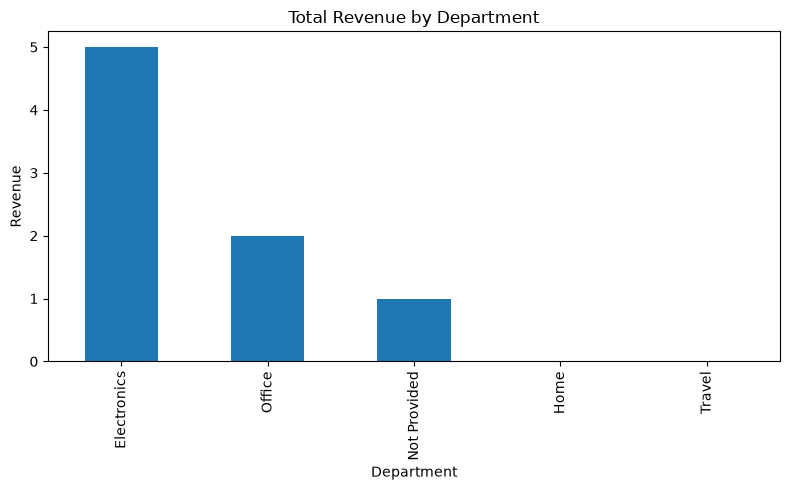

WindowsPath('08-OutputFiles/department_revenue.png')

In [78]:
# 6. Make a bar chart of total revenue by department (Foundations notebook 07), and save it to `OUT`.
import matplotlib.pyplot as plt

dept_revenue = (
    analysis.groupby('department')['revenue']
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))
dept_revenue.plot(kind='bar')
plt.title('Total Revenue by Department')
plt.xlabel('Department')
plt.ylabel('Revenue')
plt.tight_layout()
plt.show()
chart_path = OUT / 'department_revenue.png'
plt.savefig(chart_path)
plt.close()

chart_path

## 📦 Check Your Output Files
Run this last. You should see `cleaned_purchases.csv`, `revenue_by_state_department.csv`, and `travel_il_report.csv` (plus anything from the Challenge). Upload `08-OutputFiles` along with this notebook.

In [79]:
for path in sorted(OUT.rglob('*')):
    print(path)

08-OutputFiles\cleaned_purchases.csv
08-OutputFiles\department_revenue.png
08-OutputFiles\revenue_by_state_department.csv
08-OutputFiles\travel_il_report.csv


---
### 📝 Summary
This lab took a messy file all the way to a trustworthy report:
- **Inspected** before changing anything, and kept the raw data for comparison
- **Standardized** column names and text, **then** turned placeholders into real missing values
- **Fixed types**: prices with `$` and commas, a word in a number column, and mixed date formats (`format='mixed'`)
- **Removed duplicates** deliberately, and decided **column by column** whether to fill or drop
- **Created** revenue, flag, band, and discount columns with whole-column operations and `.loc[]`
- **Filtered, sorted, grouped, validated, and exported** the results

> Clean data isn't just data with fewer rows. It's data whose values, types, categories, and assumptions you've inspected well enough to support trustworthy analysis.